# Lung Cancer Dataset Preprocessing

This notebook extracts and inspects the original image dataset, creates a reproducible train/validation/test split, applies a consistent image conversion, and saves an auditable manifest. It uses the source class folders already found in this project: `Malignant cases`, `Bengin cases` (spelled this way in the source), and `Normal cases`.

**Important:** The class folders support a three-class label mapping, but they do not prove that the files are raw CT scans or that patient IDs are available. The notebook inspects the archive before processing. It will not apply CT segmentation to ordinary rendered image files, and it does not claim to exactly reproduce the cited LungCT-NET paper.

Run the notebook from top to bottom in Google Colab. Review the printed dataset inspection and sample images before continuing to the split and export steps.


## 1. Connect Google Drive and configure paths

The paths below are the exact ZIP and output paths specified for this project. The temporary extraction directory is separate from the ZIP and from the final output.


In [5]:
from pathlib import Path

DRIVE_ROOT = Path("/content/drive/MyDrive")
if not DRIVE_ROOT.is_dir():
    raise FileNotFoundError(
        "Google Drive is not mounted. In Colab, run the Drive mount cell below, "
        "approve access, then rerun this cell."
    )
print("Google Drive is mounted:", DRIVE_ROOT)

Google Drive is mounted: /content/drive/MyDrive


In [6]:
# Avoid remounting if the previous check already found Drive mounted.
if DRIVE_ROOT.is_dir():
    print("Google Drive is already mounted; skipping remount.")
else:
    from google.colab import drive

    drive.mount("/content/drive")
    if not DRIVE_ROOT.is_dir():
        raise RuntimeError(
            "Google Drive did not mount successfully. In Colab, restart the runtime, "
            "run this cell again, and approve the Drive authorization prompt."
        )
    print("Google Drive mounted successfully.")


Google Drive is already mounted; skipping remount.


In [7]:
import json
import os
import random
import re
import shutil
import zipfile
from collections import Counter, defaultdict
from datetime import datetime

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import PIL
from PIL import Image, ImageOps
import sklearn
import tensorflow as tf
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from IPython.display import display

ZIP_PATH = Path(
    "/content/drive/MyDrive/Colab Notebooks/"
    "An Image Dataset of Advanced Imaging Techniques for Lung Cancer Diagnosis.zip"
)
TEMP_DIR = Path("/content/lung_cancer_dataset_inspection")
OUTPUT_DIR = Path("/content/drive/MyDrive/Dataset/Lung_Cancer_Preprocessed_Dataset")

SEED = 42
SPLIT_RATIOS = {"train": 0.70, "validation": 0.15, "test": 0.15}
IMAGE_SIZE = (224, 224)
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}
SOURCE_CLASS_MAP = {
    "Malignant cases": "Malignant",
    "Bengin cases": "Benign",
    "Normal cases": "Normal",
}

# Leave as None unless you inspect filenames/metadata and confirm a patient-ID pattern.
# If set, it must be a regular expression with one capture group containing the patient ID.
PATIENT_ID_REGEX = None

# Augmentation is opt-in. After reviewing images and modality, set to 1 or more
# to create mild training-only variants. No horizontal/vertical flips are used.
AUGMENTATION_COPIES_PER_IMAGE = 0
AUGMENTATION_MAX_ROTATION_DEGREES = 5
AUGMENTATION_MIN_ZOOM = 0.95
AUGMENTATION_MAX_BRIGHTNESS_FACTOR = 1.05

# If OUTPUT_DIR already exists, the notebook stops unless you explicitly change this.
CONFIRM_REPLACE_OUTPUT = False

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("ZIP:", ZIP_PATH)
print("Temporary inspection folder:", TEMP_DIR)
print("Final output folder:", OUTPUT_DIR)
print("Split ratios:", SPLIT_RATIOS)
print("Classes:", list(SOURCE_CLASS_MAP.values()))

ZIP: /content/drive/MyDrive/Colab Notebooks/An Image Dataset of Advanced Imaging Techniques for Lung Cancer Diagnosis.zip
Temporary inspection folder: /content/lung_cancer_dataset_inspection
Final output folder: /content/drive/MyDrive/Dataset/Lung_Cancer_Preprocessed_Dataset
Split ratios: {'train': 0.7, 'validation': 0.15, 'test': 0.15}
Classes: ['Malignant', 'Benign', 'Normal']


## 2. Extract the archive without changing it

Extraction is limited to the temporary working folder. The ZIP file is only read. If a previous temporary extraction exists, it is replaced so inspection does not accidentally combine files from multiple copies of the archive.


In [8]:
if not ZIP_PATH.is_file():
    raise FileNotFoundError(f"Dataset ZIP was not found: {ZIP_PATH}")

if TEMP_DIR.exists():
    shutil.rmtree(TEMP_DIR)
TEMP_DIR.mkdir(parents=True)

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    bad_member = archive.testzip()
    if bad_member is not None:
        raise ValueError(f"The archive contains a damaged member: {bad_member}")

    # Reject paths that would extract outside the temporary directory.
    temp_root = TEMP_DIR.resolve()
    for member in archive.infolist():
        destination = (TEMP_DIR / member.filename).resolve()
        if destination != temp_root and temp_root not in destination.parents:
            raise ValueError(f"Unsafe path in ZIP archive: {member.filename}")
    archive.extractall(TEMP_DIR)

print("Archive extracted for inspection; original ZIP was not modified.")

Archive extracted for inspection; original ZIP was not modified.


## 3. Inspect labels, file formats, and metadata

The class mapping is based only on the source directory names. This cell locates the directory containing all three known source class folders and inspects its contents. It does not infer a class from image appearance.


In [9]:
required_source_folders = set(SOURCE_CLASS_MAP)
dataset_candidates = []
for current_root, subdirectories, _ in os.walk(TEMP_DIR):
    if required_source_folders.issubset(set(subdirectories)):
        dataset_candidates.append(Path(current_root))

if len(dataset_candidates) != 1:
    raise ValueError(
        "Could not identify exactly one dataset directory containing the expected "
        f"source folders {sorted(required_source_folders)}. Candidates: {dataset_candidates}. "
        "Inspect the extracted folder structure and update SOURCE_CLASS_MAP only if the labels are verified."
    )

SOURCE_DIR = dataset_candidates[0]
CLASS_DIRS = {source: SOURCE_DIR / source for source in SOURCE_CLASS_MAP}
print("Dataset directory:", SOURCE_DIR)
print("Verified folder-to-label mapping:")
for source_name, class_name in SOURCE_CLASS_MAP.items():
    print(f"  {source_name!r} -> {class_name!r}")

all_files = [path for path in TEMP_DIR.rglob("*") if path.is_file()]
format_counts = Counter(path.suffix.lower() or "[no extension]" for path in all_files)
xml_files = sorted(TEMP_DIR.rglob("*.xml"))
dicom_files = [path for path in all_files if path.suffix.lower() in {".dcm", ".dicom"}]
volume_files = [path for path in all_files if path.name.lower().endswith((".nii", ".nii.gz", ".mha", ".mhd", ".nrrd"))]

print("\nFile formats in archive:")
display(pd.DataFrame(format_counts.most_common(), columns=["Extension", "Files"]))
print("XML annotation/metadata files:", len(xml_files))
print("DICOM files:", len(dicom_files))
print("Medical-volume files (NIfTI/MHA/NRRD):", len(volume_files))
if xml_files:
    print("Example XML paths:", [str(path.relative_to(TEMP_DIR)) for path in xml_files[:10]])

Dataset directory: /content/lung_cancer_dataset_inspection/An Image Dataset of Advanced Imaging Techniques for Lung Cancer Diagnosis/Lung Cancer Diagnosis Dataset/Dataset
Verified folder-to-label mapping:
  'Malignant cases' -> 'Malignant'
  'Bengin cases' -> 'Benign'
  'Normal cases' -> 'Normal'

File formats in archive:


,Extension,Files
0,.jpg,1933


XML annotation/metadata files: 0
DICOM files: 0
Medical-volume files (NIfTI/MHA/NRRD): 0


In [10]:
image_records = []
unreadable_files = []
image_metadata = []

for source_folder, class_name in SOURCE_CLASS_MAP.items():
    class_dir = CLASS_DIRS[source_folder]
    paths = sorted(
        path for path in class_dir.rglob("*")
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
    )
    for path in paths:
        try:
            with Image.open(path) as image:
                image.verify()
            with Image.open(path) as image:
                image_records.append({
                    "source_path": path,
                    "source_class_folder": source_folder,
                    "class_name": class_name,
                })
                image_metadata.append({
                    "class_name": class_name,
                    "format": path.suffix.lower(),
                    "mode": image.mode,
                    "width": image.width,
                    "height": image.height,
                    "relative_path": str(path.relative_to(TEMP_DIR)),
                })
        except (OSError, ValueError) as error:
            unreadable_files.append((str(path), str(error)))

if not image_records:
    raise ValueError("No readable JPG/JPEG/PNG/BMP images were found in the mapped class folders.")

metadata_df = pd.DataFrame(image_metadata)
print("Readable image counts by class:")
display(metadata_df.groupby("class_name").size().reindex(SOURCE_CLASS_MAP.values(), fill_value=0).rename("images"))
print("\nImage formats and modes:")
display(metadata_df.groupby(["format", "mode"]).size().rename("images").reset_index())
print("\nMost common image dimensions:")
display(metadata_df.groupby(["width", "height"]).size().sort_values(ascending=False).head(15).rename("images"))
print("\nUnreadable files:", len(unreadable_files))
for path, error in unreadable_files[:10]:
    print(" ", path, "|", error[:200])
if unreadable_files:
    raise ValueError("Unreadable images were found. Resolve them before creating the final dataset.")

Readable image counts by class:


,images
class_name,
Malignant,1050
Benign,467
Normal,416



Image formats and modes:


,format,mode,images
0,.jpg,RGB,1933



Most common image dimensions:


,,images
width,height,
512,512,1932
506,331,1



Unreadable files: 0


### What kind of images are these?

JPG, PNG, and BMP files are rendered 2D image files, not raw volumetric CT data. They may depict CT slices, but their file format alone does not establish modality, intensity calibration, slice spacing, or patient identity. DICOM/volume files would be needed for many CT-specific operations. The next cell stops the image-only workflow if such medical-volume files are present, because those need an explicitly designed modality-aware path.


In [11]:
if dicom_files or volume_files:
    raise NotImplementedError(
        "DICOM or medical-volume files were found. Do not process them as ordinary RGB images. "
        "Inspect the modality, calibration, annotations, and patient IDs, then design a validated CT pipeline."
    )

if not set(metadata_df["format"]).issubset(IMAGE_EXTENSIONS):
    raise ValueError("Unexpected image format detected; update the supported-format handling after inspection.")

print(
    "Inspection result: the class folders contain rendered raster images. "
    "This notebook will use consistent RGB conversion and resizing, not CT lung segmentation."
)
print("This result does not establish whether the rendered images are CT slices or another image type.")

Inspection result: the class folders contain rendered raster images. This notebook will use consistent RGB conversion and resizing, not CT lung segmentation.
This result does not establish whether the rendered images are CT slices or another image type.


In [12]:
print("Example filenames in each class (review for scan/patient identifiers):")
for source_folder, class_name in SOURCE_CLASS_MAP.items():
    examples = [
        record["source_path"]
        for record in image_records
        if record["source_class_folder"] == source_folder
    ][:8]
    print(f"\n{class_name}:")
    for path in examples:
        print(" ", path.name)

nested_class_folders = {
    source_folder: sorted(
        path for path in class_dir.rglob("*")
        if path.is_dir() and path != class_dir
    )
    for source_folder, class_dir in CLASS_DIRS.items()
}
print("\nNested directories under class folders:", {
    class_name: len(paths)
    for class_name, paths in nested_class_folders.items()
})
print("Patient/scan IDs are not inferred from filenames or folders automatically.")
if xml_files:
    print("Review the XML files listed above for documented patient/scan IDs or annotations.")
if PATIENT_ID_REGEX is None:
    print("No verified patient-ID rule is configured; splitting will be image-level and may not prevent patient leakage.")

Example filenames in each class (review for scan/patient identifiers):

Malignant:
  Malignant (1).JPG
  Malignant (10).JPG
  Malignant (100).JPG
  Malignant (1000).JPG
  Malignant (1001).JPG
  Malignant (1002).JPG
  Malignant (1003).JPG
  Malignant (1004).JPG

Benign:
  Benign (1).JPG
  Benign (10).JPG
  Benign (100).JPG
  Benign (101).JPG
  Benign (102).JPG
  Benign (103).JPG
  Benign (104).JPG
  Benign (105).JPG

Normal:
  Normal case (1).jpg
  Normal case (10).jpg
  Normal case (100).jpg
  Normal case (101).jpg
  Normal case (102).jpg
  Normal case (103).jpg
  Normal case (104).jpg
  Normal case (105).jpg

Nested directories under class folders: {'Malignant cases': 0, 'Bengin cases': 0, 'Normal cases': 0}
Patient/scan IDs are not inferred from filenames or folders automatically.
No verified patient-ID rule is configured; splitting will be image-level and may not prevent patient leakage.


## 4. Review example images and decide on processing

The notebook does not apply the paper-inspired z-score, outlier clipping, median filter, anisotropic diffusion, K-means thresholding, or morphological lung segmentation to these raster files. Those operations require validated CT pixel values and modality-specific parameters; applying them to ordinary rendered images could remove or distort useful content. We will preserve the source pixels, convert consistently to RGB, and resize to 224×224. Neural-network-specific normalization should be applied by the training model.

The transformations from the older augmentation notebook (rotation, zoom/crop, brightness) are optional and disabled by default. Review the examples and set `AUGMENTATION_COPIES_PER_IMAGE` above zero only if these transformations are appropriate for this dataset. No augmented files are made for validation or test.


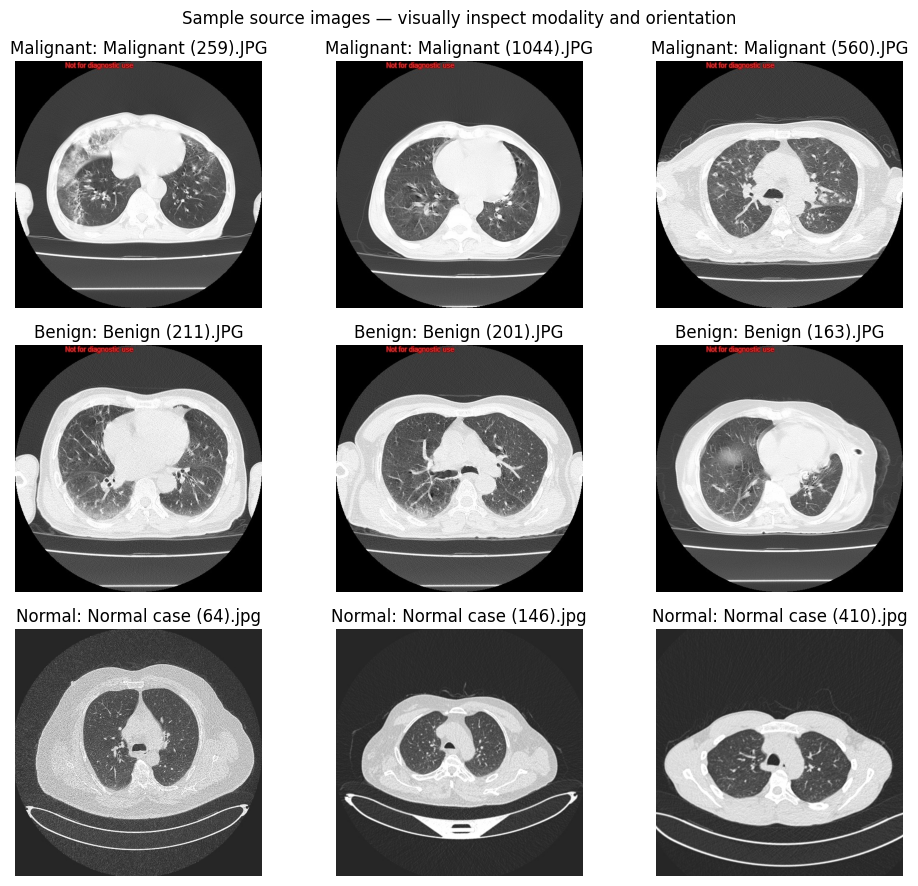

In [13]:
rng = random.Random(SEED)
examples_by_class = defaultdict(list)
for record in image_records:
    examples_by_class[record["class_name"]].append(record["source_path"])

fig, axes = plt.subplots(len(SOURCE_CLASS_MAP), 3, figsize=(10, 9))
for row, class_name in enumerate(SOURCE_CLASS_MAP.values()):
    examples = examples_by_class[class_name]
    for column in range(3):
        ax = axes[row, column]
        if examples:
            path = rng.choice(examples)
            with Image.open(path) as image:
                ax.imshow(image.convert("RGB"))
            ax.set_title(f"{class_name}: {path.name[:24]}")
        ax.axis("off")
fig.suptitle("Sample source images — visually inspect modality and orientation")
plt.tight_layout()
plt.show()

## 5. Create reproducible data splits

The 70%/15%/15% split is stratified by class when no patient identifier is confirmed. Augmentation, if enabled, happens only after splitting and only for training images. This prevents generated variants of an image from entering validation or test.

If patient/scan IDs are available, configure `PATIENT_ID_REGEX` in the setup cell using a verified filename pattern. In that case this notebook uses grouped splits and checks that every class is represented in all splits. Grouped splitting may not produce exactly stratified class proportions; the printed counts must be reviewed. Without a verified ID rule, the fallback is image-level splitting and cannot guarantee that related scans are separated.


In [14]:
CLASS_NAMES = list(SOURCE_CLASS_MAP.values())
records_df = pd.DataFrame(image_records)
records_df["label_index"] = records_df["class_name"].map(
    {name: index for index, name in enumerate(CLASS_NAMES)}
    )
records_df["patient_id"] = None

if PATIENT_ID_REGEX is not None:
    patient_pattern = re.compile(PATIENT_ID_REGEX)
    patient_ids = []
    for source_path in records_df["source_path"]:
        match = patient_pattern.search(source_path.name)
        if match is None or match.lastindex is None:
            raise ValueError(
                f"Patient-ID pattern did not return a capture group for {source_path.name!r}. "
                "Update PATIENT_ID_REGEX after reviewing the filenames."
            )
        patient_ids.append(match.group(1))
    records_df["patient_id"] = patient_ids

    groups = records_df["patient_id"].to_numpy()
    labels = records_df["label_index"].to_numpy()
    first_splitter = GroupShuffleSplit(n_splits=1, test_size=SPLIT_RATIOS["test"], random_state=SEED)
    train_validation_indices, test_indices = next(
        first_splitter.split(records_df, labels, groups)
    )
    remaining_fraction = SPLIT_RATIOS["validation"] / (
        SPLIT_RATIOS["train"] + SPLIT_RATIOS["validation"]
    )
    second_splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=remaining_fraction,
        random_state=SEED + 1,
    )
    train_relative, validation_relative = next(
        second_splitter.split(
            records_df.iloc[train_validation_indices],
            labels[train_validation_indices],
            groups[train_validation_indices],
        )
    )
    train_indices = train_validation_indices[train_relative]
    validation_indices = train_validation_indices[validation_relative]
    records_df["split"] = None
    records_df.loc[train_indices, "split"] = "train"
    records_df.loc[validation_indices, "split"] = "validation"
    records_df.loc[test_indices, "split"] = "test"
    print("Grouped split used; patient IDs stay together.")
else:
    train_validation, test_part = train_test_split(
        records_df,
        test_size=SPLIT_RATIOS["test"],
        random_state=SEED,
        stratify=records_df["label_index"],
    )
    validation_fraction_of_remaining = SPLIT_RATIOS["validation"] / (
        SPLIT_RATIOS["train"] + SPLIT_RATIOS["validation"]
    )
    train_part, validation_part = train_test_split(
        train_validation,
        test_size=validation_fraction_of_remaining,
        random_state=SEED + 1,
        stratify=train_validation["label_index"],
    )
    records_df["split"] = None
    records_df.loc[train_part.index, "split"] = "train"
    records_df.loc[validation_part.index, "split"] = "validation"
    records_df.loc[test_part.index, "split"] = "test"
    print("Stratified image-level split used; patient-level separation is not verified.")

if records_df["split"].isna().any():
    raise RuntimeError("Some images were not assigned to a split.")

split_counts = pd.crosstab(records_df["split"], records_df["class_name"]).reindex(
    index=["train", "validation", "test"], columns=CLASS_NAMES, fill_value=0
)
display(split_counts)
if (split_counts == 0).any().any():
    raise ValueError("At least one class is missing from a split; review group IDs or split proportions.")

if PATIENT_ID_REGEX is not None:
    split_patient_sets = {
        split: set(records_df.loc[records_df["split"] == split, "patient_id"])
        for split in ("train", "validation", "test")
    }
    if (split_patient_sets["train"] & split_patient_sets["validation"]
        or split_patient_sets["train"] & split_patient_sets["test"]
        or split_patient_sets["validation"] & split_patient_sets["test"]):
        raise RuntimeError("A patient ID appears in more than one split.")
    print("Verified: no patient IDs overlap across splits.")

Stratified image-level split used; patient-level separation is not verified.


class_name,Malignant,Benign,Normal
split,,,
train,735,327,291
validation,157,70,63
test,158,70,62


## 6. Prepare the output directory

The final folders use `train`, `validation`, and `test`, with the exact class folder names `Benign`, `Malignant`, and `Normal`. To protect existing results, this notebook stops if the output already exists. Only set `CONFIRM_REPLACE_OUTPUT = True` after you have reviewed the path and explicitly decided to replace it.


In [15]:
if OUTPUT_DIR.exists():
    if not CONFIRM_REPLACE_OUTPUT:
        raise FileExistsError(
            f"Output already exists: {OUTPUT_DIR}. Set CONFIRM_REPLACE_OUTPUT = True "
            "in the configuration cell only if you explicitly want to replace it."
        )
    print("Explicit replacement confirmation received; removing:", OUTPUT_DIR)
    shutil.rmtree(OUTPUT_DIR)

for split_name in ("train", "validation", "test"):
    for class_name in CLASS_NAMES:
        (OUTPUT_DIR / split_name / class_name).mkdir(parents=True, exist_ok=True)
(OUTPUT_DIR / "metadata").mkdir(parents=True, exist_ok=True)
print("Created output folders under:", OUTPUT_DIR)

Created output folders under: /content/drive/MyDrive/Dataset/Lung_Cancer_Preprocessed_Dataset


## 7. Convert images consistently and augment training only

For raster images, the processing is EXIF orientation correction, RGB conversion, and resize to 224×224. We do not apply z-score normalization or CT segmentation because the source files are rendered images without verified CT intensity calibration. The final PNG pixel values remain in the usual 0–255 range.

If enabled, the optional augmentation uses small rotation, a mild zoom/crop, and a small brightness adjustment on training images only. These transformations are not validated for every medical imaging modality; keep augmentation disabled unless visual inspection and domain knowledge support it.


In [16]:
def resize_rgb(source_path):
    """Read a raster image, correct orientation, convert to RGB, and resize."""
    with Image.open(source_path) as image:
        image = ImageOps.exif_transpose(image).convert("RGB")
        resampling = getattr(Image, "Resampling", Image).LANCZOS
        return image.resize(IMAGE_SIZE, resampling)

def make_training_variant(image, rng):
    """Create one mild, configurable training-only image variant."""
    angle = rng.uniform(
        -AUGMENTATION_MAX_ROTATION_DEGREES,
        AUGMENTATION_MAX_ROTATION_DEGREES,
    )
    variant = image.rotate(angle, resample=Image.Resampling.BILINEAR)

    zoom = rng.uniform(AUGMENTATION_MIN_ZOOM, 1.0)
    width, height = variant.size
    crop_width = max(1, int(width * zoom))
    crop_height = max(1, int(height * zoom))
    left = (width - crop_width) // 2
    top = (height - crop_height) // 2
    variant = variant.crop((left, top, left + crop_width, top + crop_height))
    variant = variant.resize(IMAGE_SIZE, Image.Resampling.BILINEAR)

    brightness = rng.uniform(1 / AUGMENTATION_MAX_BRIGHTNESS_FACTOR, AUGMENTATION_MAX_BRIGHTNESS_FACTOR)
    from PIL import ImageEnhance
    return ImageEnhance.Brightness(variant).enhance(brightness)

augmentation_rng = random.Random(SEED)
manifest_rows = []
output_number = 0

for record in records_df.to_dict(orient="records"):
    source_path = Path(record["source_path"])
    split_name = record["split"]
    class_name = record["class_name"]
    output_number += 1
    output_name = f"{class_name.lower()}_{output_number:06d}.png"
    output_path = OUTPUT_DIR / split_name / class_name / output_name

    image = resize_rgb(source_path)
    image.save(output_path, format="PNG")
    manifest_rows.append({
        "source_file": str(source_path),
        "output_file": str(output_path),
        "class_name": class_name,
        "split": split_name,
        "patient_id": record["patient_id"],
        "is_augmented": False,
        "augmentation_index": 0,
    })

    if split_name == "train":
        for augmentation_index in range(1, AUGMENTATION_COPIES_PER_IMAGE + 1):
            variant = make_training_variant(image, augmentation_rng)
            variant_path = OUTPUT_DIR / split_name / class_name / (
                f"{Path(output_name).stem}_aug{augmentation_index:02d}.png"
            )
            variant.save(variant_path, format="PNG")
            manifest_rows.append({
                "source_file": str(source_path),
                "output_file": str(variant_path),
                "class_name": class_name,
                "split": split_name,
                "patient_id": record["patient_id"],
                "is_augmented": True,
                "augmentation_index": augmentation_index,
            })

manifest_df = pd.DataFrame(manifest_rows)
print("Saved originals:", int((~manifest_df["is_augmented"]).sum()))
print("Saved training variants:", int(manifest_df["is_augmented"].sum()))
print("Augmentation copies per training image:", AUGMENTATION_COPIES_PER_IMAGE)

Saved originals: 1933
Saved training variants: 0
Augmentation copies per training image: 0


## 8. Verify saved images and review before/after examples

Every saved image is reopened and checked for the expected 224×224 size and RGB channels. This catches incomplete writes and provides a final integrity check before the manifest and configuration are saved.


Verified 1933 saved image files: 224×224, RGB.


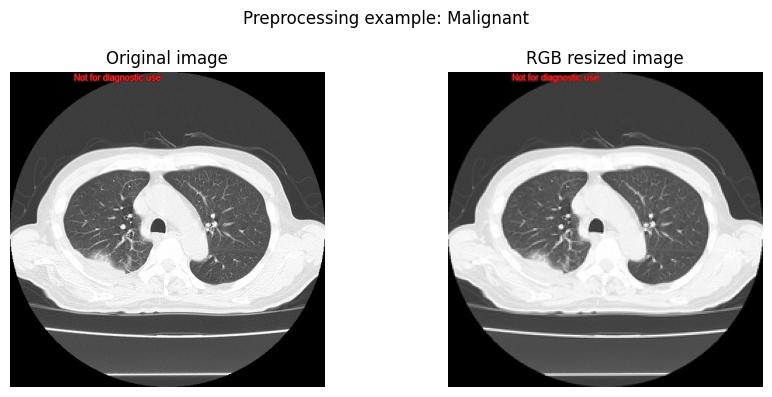

In [17]:
verification_errors = []
for output_path in manifest_df["output_file"]:
    try:
        with Image.open(output_path) as image:
            if image.size != IMAGE_SIZE or image.mode != "RGB":
                verification_errors.append(
                    (output_path, image.size, image.mode)
                )
            image.verify()
    except (OSError, ValueError) as error:
        verification_errors.append((output_path, str(error)))

if verification_errors:
    for error in verification_errors[:10]:
        print(error)
    raise ValueError(f"{len(verification_errors)} saved image(s) failed verification.")
print(f"Verified {len(manifest_df)} saved image files: {IMAGE_SIZE[0]}×{IMAGE_SIZE[1]}, RGB.")

example_record = next(record for record in manifest_rows if record["split"] == "train")
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
with Image.open(example_record["source_file"]) as original:
    axes[0].imshow(original.convert("RGB"))
axes[0].set_title("Original image")
axes[0].axis("off")
with Image.open(example_record["output_file"]) as processed:
    axes[1].imshow(processed)
axes[1].set_title("RGB resized image")
axes[1].axis("off")
fig.suptitle(f"Preprocessing example: {example_record['class_name']}")
plt.tight_layout()
plt.show()

## 9. Save the split manifest, class counts, and configuration

The manifest records each output file, its original source, class, split, optional patient ID, and whether it is an augmented training variant. Class counts distinguish original images from generated variants.


In [18]:
metadata_dir = OUTPUT_DIR / "metadata"
manifest_path = metadata_dir / "split_manifest.csv"
counts_path = metadata_dir / "class_counts.csv"
config_path = metadata_dir / "preprocessing_config.json"

manifest_df.to_csv(manifest_path, index=False)

class_counts_df = (
    manifest_df.groupby(["split", "class_name", "is_augmented"])
    .size()
    .rename("image_count")
    .reset_index()
)
class_counts_df.to_csv(counts_path, index=False)

preprocessing_config = {
    "created_at": datetime.now().isoformat(timespec="seconds"),
    "zip_path": str(ZIP_PATH),
    "source_directory_inside_extraction": str(SOURCE_DIR.relative_to(TEMP_DIR)),
    "output_directory": str(OUTPUT_DIR),
    "source_class_map": SOURCE_CLASS_MAP,
    "output_class_names": CLASS_NAMES,
    "seed": SEED,
    "split_ratios_requested": SPLIT_RATIOS,
    "split_method": "grouped by configured patient ID" if PATIENT_ID_REGEX else "stratified image-level",
    "patient_id_regex": PATIENT_ID_REGEX,
    "patient_level_separation_verified": PATIENT_ID_REGEX is not None,
    "image_size_width_height": list(IMAGE_SIZE),
    "output_format": "PNG RGB",
    "raster_processing": ["EXIF orientation correction", "RGB conversion", "resize with LANCZOS"],
    "ct_specific_segmentation_applied": False,
    "ct_segmentation_note": (
        "Not applied: source files are rendered raster images; CT intensity calibration and "
        "validated modality-specific segmentation settings are not established."
    ),
    "augmentation_copies_per_training_image": AUGMENTATION_COPIES_PER_IMAGE,
    "augmentation_settings": {
        "rotation_degrees_each_direction": AUGMENTATION_MAX_ROTATION_DEGREES,
        "minimum_zoom": AUGMENTATION_MIN_ZOOM,
        "maximum_brightness_factor": AUGMENTATION_MAX_BRIGHTNESS_FACTOR,
        "training_only": True,
    },
    "python_version": os.sys.version,
    "tensorflow_version": tf.__version__,
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "pillow_version": PIL.__version__,
    "scikit_learn_version": sklearn.__version__,
    "limitations": [
        "Directory labels are used as supplied and are not independently clinically verified.",
        "Raster image files do not establish that the source is raw CT data.",
        "Without a verified patient/scan ID rule, image-level splitting can leak related images across splits.",
        "The preprocessing is not an exact reproduction of the cited paper.",
    ],
}
with config_path.open("w") as config_file:
    json.dump(preprocessing_config, config_file, indent=2)

print("Saved:", manifest_path)
print("Saved:", counts_path)
print("Saved:", config_path)

Saved: /content/drive/MyDrive/Dataset/Lung_Cancer_Preprocessed_Dataset/metadata/split_manifest.csv
Saved: /content/drive/MyDrive/Dataset/Lung_Cancer_Preprocessed_Dataset/metadata/class_counts.csv
Saved: /content/drive/MyDrive/Dataset/Lung_Cancer_Preprocessed_Dataset/metadata/preprocessing_config.json


## 10. Final counts and output summary

Use the `train`, `validation`, and `test` directories directly with TensorFlow/Keras directory-based image loaders. The manifest provides the exact source-to-output mapping for auditing and reuse.


In [19]:
final_counts = pd.crosstab(
    manifest_df["split"],
    manifest_df["class_name"],
).reindex(index=["train", "validation", "test"], columns=CLASS_NAMES, fill_value=0)
final_counts["TOTAL"] = final_counts.sum(axis=1)
final_counts.loc["TOTAL"] = final_counts.sum(axis=0)
display(final_counts)

print("\nOutput structure:")
for path in sorted(OUTPUT_DIR.rglob("*")):
    if path.is_dir():
        print(" ", path.relative_to(OUTPUT_DIR), "/")
print("\nPreprocessed dataset saved to:", OUTPUT_DIR)
print("Manifest:", manifest_path)
print("\nPreprocessing performed: RGB conversion, EXIF orientation correction, and resize to 224×224.")
print("CT-specific segmentation was not applied; inspect modality and patient-level metadata before scientific use.")

class_name,Malignant,Benign,Normal,TOTAL
split,,,,
train,735,327,291,1353
validation,157,70,63,290
test,158,70,62,290
TOTAL,1050,467,416,1933



Output structure:
  metadata /
  test /
  test/Benign /
  test/Malignant /
  test/Normal /
  train /
  train/Benign /
  train/Malignant /
  train/Normal /
  validation /
  validation/Benign /
  validation/Malignant /
  validation/Normal /

Preprocessed dataset saved to: /content/drive/MyDrive/Dataset/Lung_Cancer_Preprocessed_Dataset
Manifest: /content/drive/MyDrive/Dataset/Lung_Cancer_Preprocessed_Dataset/metadata/split_manifest.csv

Preprocessing performed: RGB conversion, EXIF orientation correction, and resize to 224×224.
CT-specific segmentation was not applied; inspect modality and patient-level metadata before scientific use.
